# Stream C - Results

Trains a lightweight classifier from stance/evidence features.


In [1]:
from pathlib import Path
import sys, os, json, pickle, re, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd

def find_repo_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "data").exists() and (q / "src").exists():
            return q
    raise RuntimeError("Could not find repo root.")

ROOT = find_repo_root()
sys.path.insert(0, str(ROOT))

from src.utils.paths import STREAM_C_CACHE, STREAM_A_CACHE, STREAM_B_CACHE, ALL_MANIFEST, FIGURES, TABLES

STREAM_C_CACHE.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
print("ROOT:", ROOT)
print("STREAM_C_CACHE:", STREAM_C_CACHE)


ROOT: E:\eve-rag
STREAM_C_CACHE: E:\eve-rag\cache\stream_c


In [2]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, confusion_matrix, roc_curve
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
STANCE_DIR = STREAM_C_CACHE / "stance_scores"; RESULT_DIR = STREAM_C_CACHE / "results"; RESULT_DIR.mkdir(parents=True, exist_ok=True)
scores_path = STANCE_DIR / "stream_c_stance_scores_all.csv"
if not scores_path.exists(): raise FileNotFoundError(f"Missing {scores_path}. Run stance scoring first.")
df = pd.read_csv(scores_path, low_memory=False)
print(df.shape); display(df.groupby(["dataset", "split"]).size().reset_index(name="rows"))


(97361, 13)


,dataset,split,rows
0,mmfakebench,test,10000
1,mmfakebench,val,1000
2,newsclippings,test,7264
3,newsclippings,train,71072
4,newsclippings,val,7024
5,verite,test,1001


In [3]:
FEATURE_COLS = ["stance_similarity", "caption_len", "evidence_len", "len_ratio", "support_score", "contradiction_score", "neutral_score"]
train_df = df[(df["dataset"] == "newsclippings") & (df["split"] == "train")].copy()
val_df = df[(df["dataset"] == "newsclippings") & (df["split"] == "val")].copy()
test_nc = df[(df["dataset"] == "newsclippings") & (df["split"] == "test")].copy()
test_mmfake = df[(df["dataset"] == "mmfakebench") & (df["split"] == "test")].copy()
test_verite = df[(df["dataset"] == "verite") & (df["split"] == "test")].copy()
clf = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("lr", LogisticRegression(max_iter=1000, class_weight="balanced"))])
clf.fit(train_df[FEATURE_COLS], train_df["label"].astype(int))
pickle.dump({"model": clf, "feature_cols": FEATURE_COLS}, open(RESULT_DIR / "stream_c_model.pkl", "wb"), protocol=4)
print("Trained Stream C model.")


Trained Stream C model.


In [4]:
def metrics(y, score):
    pred = (score >= 0.5).astype(int)
    out = {"acc": accuracy_score(y, pred)*100, "precision": precision_score(y, pred, zero_division=0)*100, "recall": recall_score(y, pred, zero_division=0)*100, "f1": f1_score(y, pred, zero_division=0)*100, "auroc": roc_auc_score(y, score)*100 if len(np.unique(y))>1 else np.nan}
    return {k: round(v, 2) if not pd.isna(v) else v for k, v in out.items()}
rows=[]; preds=[]
for name, sub in [("newsclippings_val", val_df), ("newsclippings_test", test_nc), ("mmfakebench_test", test_mmfake), ("verite_test", test_verite)]:
    y=sub["label"].astype(int).values; score=clf.predict_proba(sub[FEATURE_COLS])[:,1]; pred=(score>=0.5).astype(int)
    rows.append({"dataset":name, **metrics(y, score)})
    tmp=sub[["pair_id","dataset","split","label"]].copy(); tmp["stream_c_score"]=score; tmp["stream_c_pred"]=pred; tmp["eval_dataset"]=name; preds.append(tmp)
results=pd.DataFrame(rows); pred_df=pd.concat(preds, ignore_index=True)
results.to_csv(TABLES / "stream_c_results.csv", index=False); pred_df.to_csv(RESULT_DIR / "stream_c_predictions.csv", index=False)
display(results)


,dataset,acc,precision,recall,f1,auroc
0,newsclippings_val,50.75,50.80,47.78,49.24,51.45
1,newsclippings_test,52.04,52.15,49.37,50.72,52.17
2,mmfakebench_test,30.62,93.06,0.96,1.89,61.85
3,verite_test,33.77,0.00,0.00,0.00,43.58


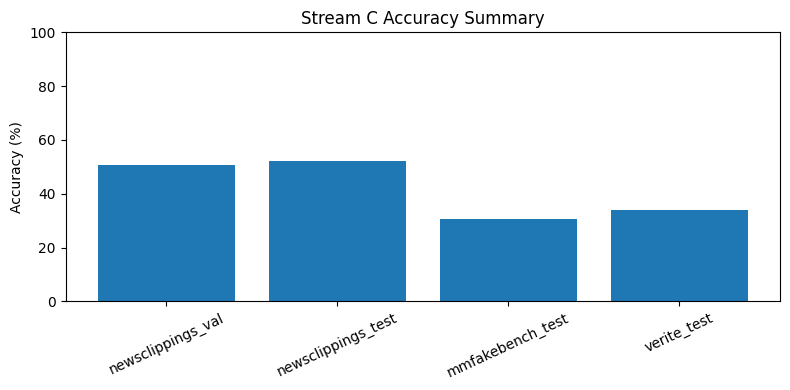

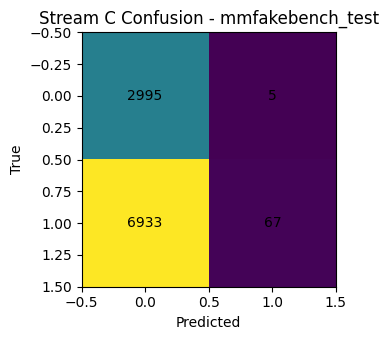

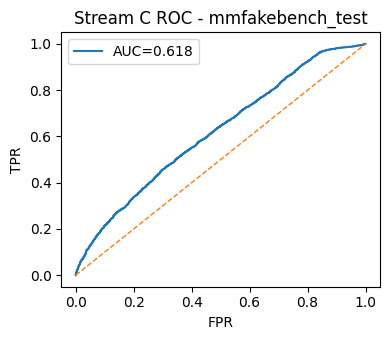

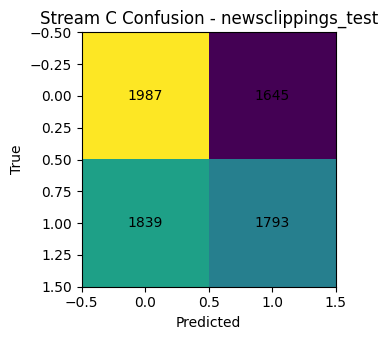

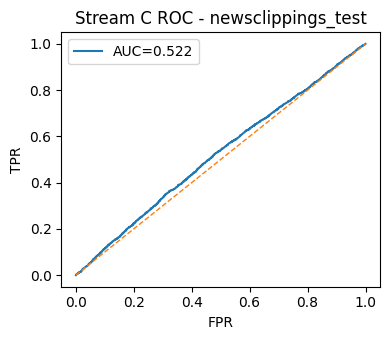

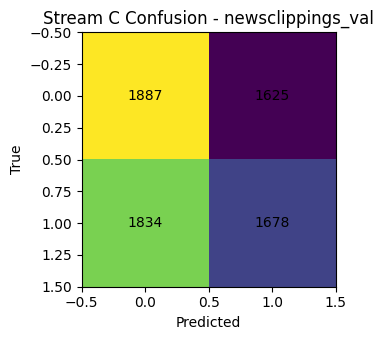

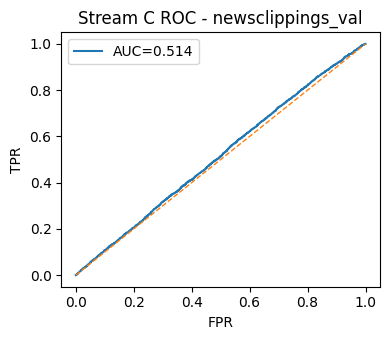

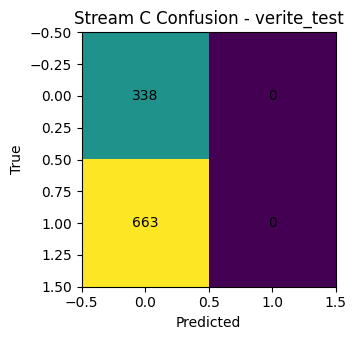

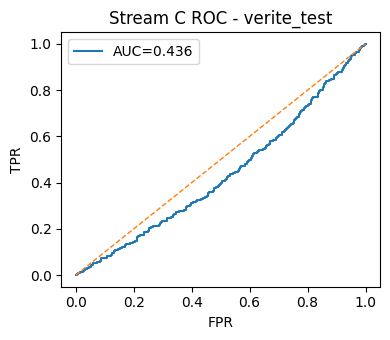

Stream C results complete.


In [5]:
fig, ax = plt.subplots(figsize=(8,4)); ax.bar(results["dataset"], results["acc"]); ax.set_title("Stream C Accuracy Summary"); ax.set_ylabel("Accuracy (%)"); ax.set_ylim(0,100); ax.tick_params(axis="x", rotation=25); fig.tight_layout(); fig.savefig(FIGURES / "stream_c_summary_bar.png", dpi=200, bbox_inches="tight"); plt.show()
for eval_name, sub in pred_df.groupby("eval_dataset"):
    y=sub["label"].astype(int).values; pred=sub["stream_c_pred"].astype(int).values; score=sub["stream_c_score"].astype(float).values
    cm=confusion_matrix(y,pred); fig,ax=plt.subplots(figsize=(4,3.5)); ax.imshow(cm); ax.set_title(f"Stream C Confusion - {eval_name}"); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    for i in range(2):
        for j in range(2): ax.text(j,i,str(cm[i,j]),ha="center",va="center")
    fig.tight_layout(); fig.savefig(FIGURES / f"stream_c_confusion_{eval_name}.png", dpi=200, bbox_inches="tight"); plt.show()
    if len(np.unique(y))>1:
        fpr,tpr,_=roc_curve(y,score); auc=roc_auc_score(y,score); fig,ax=plt.subplots(figsize=(4,3.5)); ax.plot(fpr,tpr,label=f"AUC={auc:.3f}"); ax.plot([0,1],[0,1],"--",linewidth=1); ax.set_title(f"Stream C ROC - {eval_name}"); ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.legend(); fig.tight_layout(); fig.savefig(FIGURES / f"stream_c_roc_{eval_name}.png", dpi=200, bbox_inches="tight"); plt.show()
print("Stream C results complete.")
